# PetroTwin fuel-market EDA

A compact analysis of the accepted event-level dataset, with enough diagnostics to judge coverage, variation, missingness, and possible relationships. It resolves `data/processed/current.json` at run time and never edits source or processed data.

**Read the quality-audit notebook first.** Charts are descriptive; they do not establish causality or approve features for a forecast. The modeling target, forecast origin, and horizon still require agreement with M3.


In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/processed/current.json").is_file()), None)
if root is None:
    raise FileNotFoundError("Open this notebook inside a PetroTwin checkout")
pointer = json.loads((root / "data/processed/current.json").read_text(encoding="utf-8"))
run_dir = root / "data/processed" / pointer["path"]
panel = pd.read_csv(run_dir / "fuel_market_panel.csv")
market = pd.read_csv(run_dir / "market_observation.csv")
quality = json.loads((run_dir / "quality_report.json").read_text(encoding="utf-8"))
fig_dir = root / "reports/figures/eda"
fig_dir.mkdir(parents=True, exist_ok=True)

panel["effective_at_local"] = pd.to_datetime(panel["effective_at_local"], utc=True).dt.tz_convert("Asia/Ho_Chi_Minh")
panel["event_date"] = panel["effective_at_local"].dt.date
for col in ["brent_observation_date", "fx_observation_date"]:
    panel[col] = pd.to_datetime(panel[col], errors="coerce")
market["observation_date"] = pd.to_datetime(market["observation_date"], errors="coerce")
panel["price_value"] = pd.to_numeric(panel["price_value"], errors="coerce")
panel["price_change_value"] = pd.to_numeric(panel["price_change_value"], errors="coerce")
market["value"] = pd.to_numeric(market["value"], errors="coerce")
product_names = panel.groupby("product_id")["source_product_name"].first().to_dict()
run_id = pointer["run_id"]
print(f"Run {run_id} | {pointer['schema_version']} | {len(panel):,} events | "
      f"{panel['event_date'].min()} to {panel['event_date'].max()}")


Run 28b22922e761cb08a8d8 | petrotwin-data-v3 | 1,390 events | 2018-08-22 to 2026-10-22


## 1. Snapshot and product-level metrics

The table combines scale, price level/spread, reported-change behavior, event cadence, and feature coverage. Gap statistics are calculated between distinct event dates within each product, not between individual fuel rows.


In [2]:
rows = []
for product_id, group in panel.groupby("product_id", sort=True):
    dates = pd.Series(pd.to_datetime(group["event_date"].drop_duplicates()).sort_values())
    gaps = dates.diff().dt.days.dropna()
    prices = group["price_value"].dropna()
    changes = group["price_change_value"].dropna()
    span_days = (dates.max() - dates.min()).days if len(dates) else 0
    rows.append({
        "product_id": product_id, "source_name": product_names.get(product_id, product_id),
        "events": len(group), "distinct_dates": group["event_date"].nunique(),
        "first_event": dates.min().date() if len(dates) else None,
        "last_event": dates.max().date() if len(dates) else None, "span_days": span_days,
        "price_min": prices.min(), "price_median": prices.median(), "price_max": prices.max(),
        "price_std": prices.std(), "change_median": changes.median(),
        "change_missing_pct": 100 * group["price_change_value"].isna().mean(),
        "median_gap_days": gaps.median() if len(gaps) else np.nan,
        "p90_gap_days": gaps.quantile(.90) if len(gaps) else np.nan,
        "max_gap_days": gaps.max() if len(gaps) else np.nan,
        "brent_missing_pct": 100 * group["brent_usd_per_barrel"].isna().mean(),
        "fx_missing_pct": 100 * group["usd_vnd_rate"].isna().mean(),
        "fund_verified_pct": 100 * group["stabilization_fund_subsidy"].notna().mean(),
    })
product_summary = pd.DataFrame(rows).sort_values(["events", "product_id"], ascending=[False, True]).reset_index(drop=True)
change_counts = pd.Series({
    "increase": int(panel["price_change_value"].gt(0).sum()),
    "decrease": int(panel["price_change_value"].lt(0).sum()),
    "unchanged": int(panel["price_change_value"].eq(0).sum()),
    "missing": int(panel["price_change_value"].isna().sum()),
}, name="fuel events")
fund_counts = panel["stabilization_fund_subsidy"].value_counts(dropna=False).rename(
    index={0.0:"verified no spending", 1.0:"verified spending", np.nan:"unverified"})
kpis = pd.DataFrame([
    {"run_id":run_id, "fuel_events":len(panel), "distinct_event_dates":panel["event_date"].nunique(),
     "market_rows":len(market), "brent_missing_rows":int(market.loc[market.series_id.eq("brent_dated_usd_bbl"),"value"].isna().sum()),
     "quarantined_rows":int(quality["integrated"]["quarantined_rows"]),
     "verified_fund_events":int(panel["stabilization_fund_subsidy"].notna().sum()),
     "unverified_fund_events":int(panel["stabilization_fund_subsidy"].isna().sum())}
])
display(kpis)
display(product_summary.round(2))
display(change_counts.to_frame(), fund_counts.rename("events").to_frame())


,run_id,fuel_events,distinct_event_dates,market_rows,brent_missing_rows,quarantined_rows,verified_fund_events,unverified_fund_events
0,28b22922e761cb08a8d8,1390,310,4528,62,64,565,825


,product_id,source_name,events,distinct_dates,first_event,last_event,span_days,price_min,price_median,price_max,price_std,change_median,change_missing_pct,median_gap_days,p90_gap_days,max_gap_days,brent_missing_pct,fx_missing_pct,fund_verified_pct
0,diesel_005s_ii,"Dầu DO 0,05S-II",310,310,2018-08-22,2026-10-22,2983,9850,18980.0,44780,5252.94,0.0,0.32,7.0,15.0,21.0,0.32,0.32,39.35
1,gasoline_e5_ron92_ii,Xăng E5 RON 92-II,310,310,2018-08-22,2026-10-22,2983,10940,20500.0,31300,3272.66,0.0,0.32,7.0,15.0,21.0,0.32,0.32,40.32
2,gasoline_ron95_iii,Xăng RON 95-III,287,287,2018-08-22,2026-05-28,2836,11630,21230.0,33840,3451.13,0.0,0.35,8.0,15.0,21.0,0.35,0.35,40.42
3,kerosene_ko,Dầu KO,269,269,2018-08-22,2026-03-07,2754,7880,18620.0,35090,3979.55,0.0,0.37,9.0,15.0,21.0,0.37,0.37,40.52
4,diesel_0001s_v,"Dầu DO 0,001S-V",119,119,2024-09-26,2026-10-22,756,17430,19360.0,44980,6358.72,0.0,0.00,7.0,7.0,11.0,0.00,0.00,64.71
5,gasoline_e10_ron95_iii,Xăng E10 RON 95-III,74,74,2025-07-31,2026-10-22,448,18460,21315.0,31420,2945.12,0.0,0.00,7.0,7.0,8.0,0.00,0.00,21.62
6,diesel_0005s_iv,"Dầu DO 0,005S-IV",10,10,2018-08-22,2019-01-01,132,14950,17920.0,18660,1283.64,-70.0,10.00,15.0,15.2,16.0,10.00,10.00,0.00
7,gasoline_ron95_iv,Xăng RON 95-IV,10,10,2018-08-22,2019-01-01,132,17800,21315.0,22540,1763.39,-310.0,10.00,15.0,15.2,16.0,10.00,10.00,0.00
8,fuel_oil_35s,"Dầu FO 3,5%S",1,1,2024-05-30,2024-05-30,0,17530,17530.0,17530,NaN,17530.0,0.00,NaN,NaN,NaN,0.00,0.00,0.00


,fuel events
increase,666
decrease,653
unchanged,65
missing,6


,events
stabilization_fund_subsidy,
NaN,825
verified no spending,435
verified spending,130


## 2. Coverage and event cadence

Sparse products have short or discontinued histories. Median and 90th-percentile gaps are descriptive; they do not imply a missing price event.


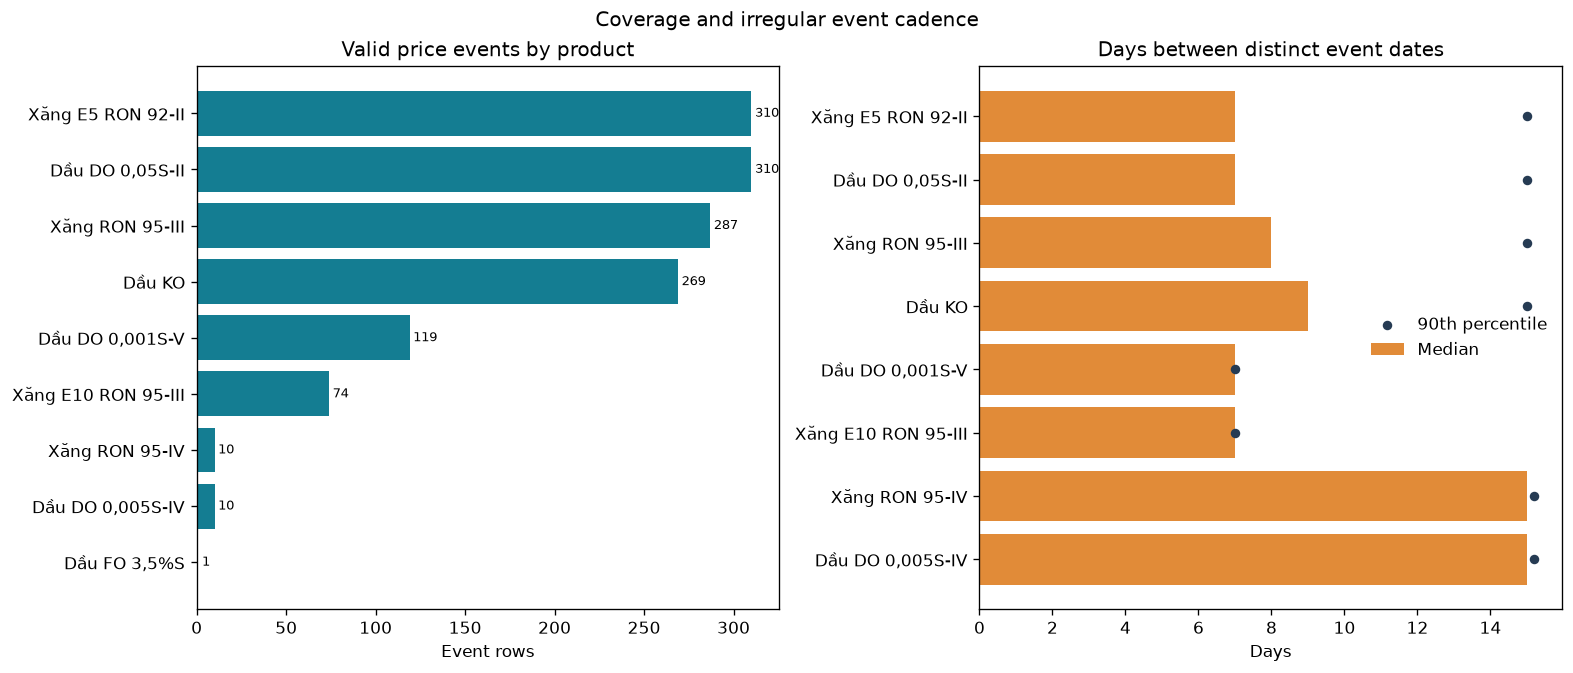

In [3]:
coverage = product_summary.sort_values("events")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
labels = [product_names.get(p, p) for p in coverage["product_id"]]
axes[0].barh(labels, coverage["events"], color="#147d92")
axes[0].set_title("Valid price events by product")
axes[0].set_xlabel("Event rows")
for y, value in enumerate(coverage["events"]): axes[0].text(value + 2, y, str(value), va="center", fontsize=8)
axes[1].barh(labels, coverage["median_gap_days"], color="#e18b38", label="Median")
axes[1].scatter(coverage["p90_gap_days"], np.arange(len(coverage)), color="#263b53", s=22, label="90th percentile")
axes[1].set_title("Days between distinct event dates")
axes[1].set_xlabel("Days")
axes[1].legend(frameon=False)
fig.suptitle("Coverage and irregular event cadence")
fig.savefig(fig_dir / "01_coverage_and_gaps.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)


## 3. Price histories and reported changes

Price levels are nominal VND/liter; no inflation adjustment is applied. The boxplots use the source-reported signed change, not a difference reconstructed by this notebook.


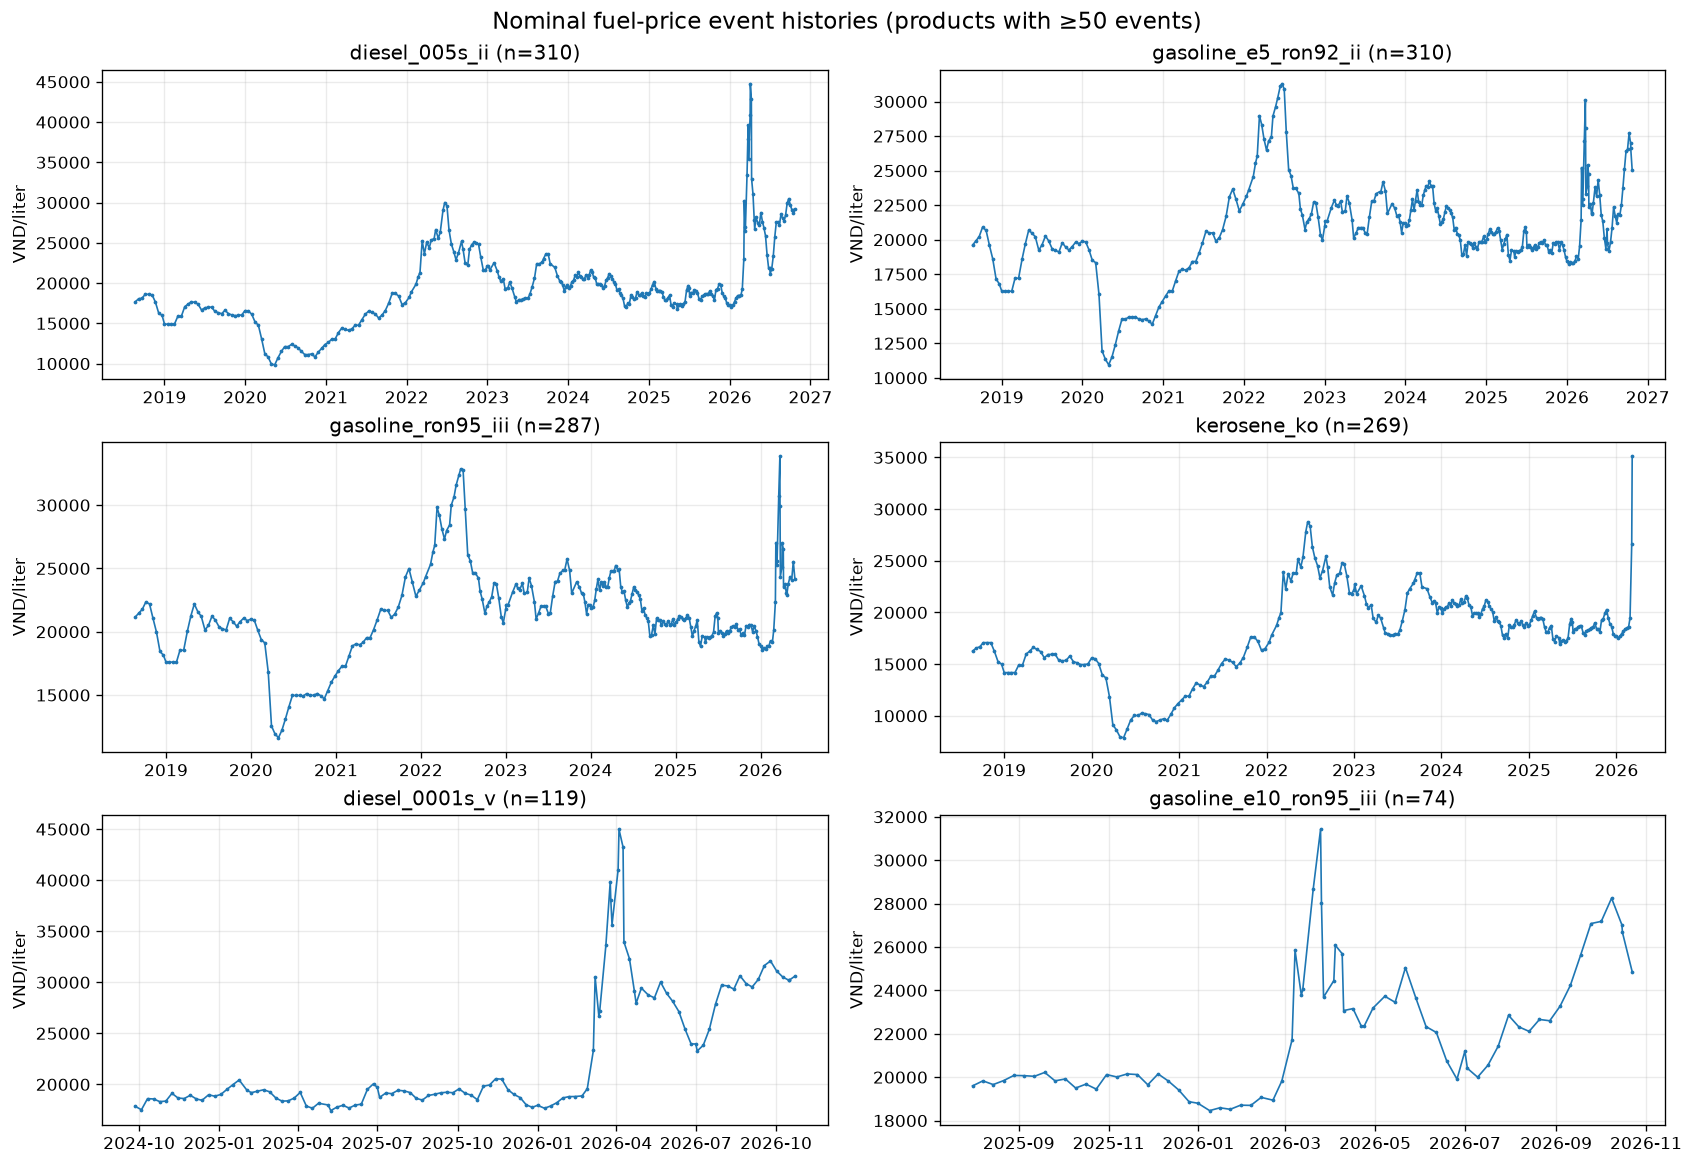

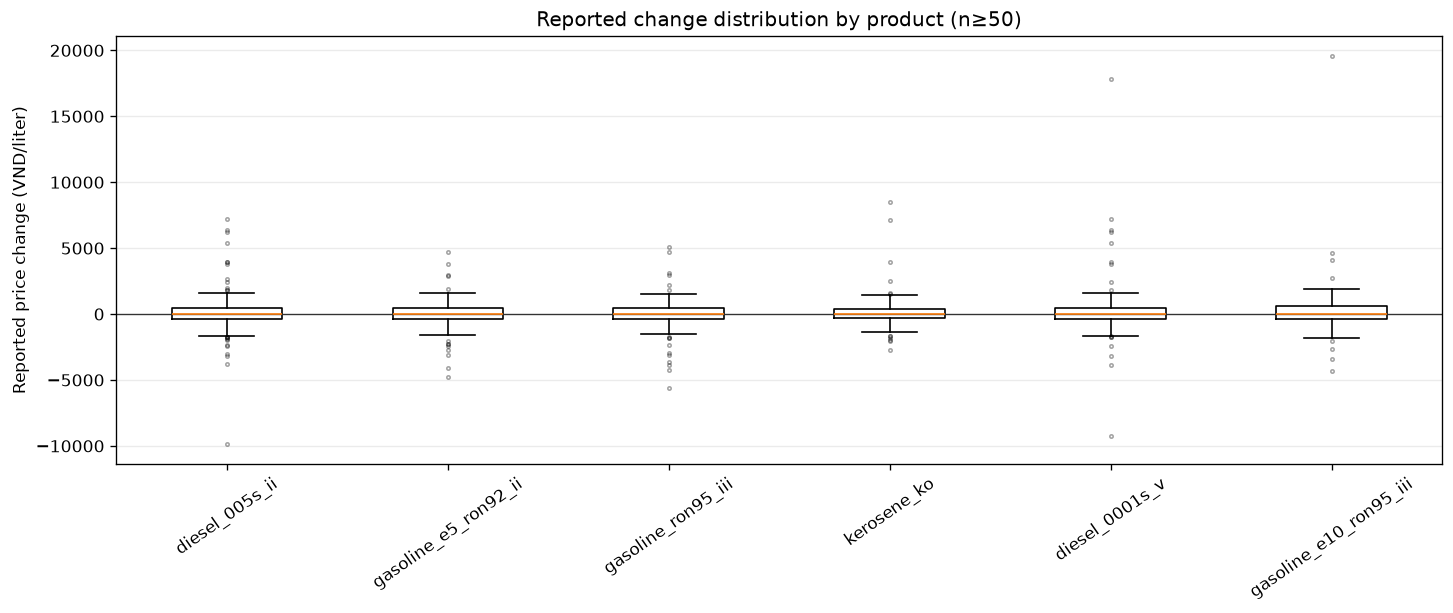

In [4]:
eligible = product_summary.loc[product_summary.events.ge(50), "product_id"].tolist()
ncols = 2
nrows = math.ceil(len(eligible) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2*nrows), squeeze=False, constrained_layout=True)
for ax, product_id in zip(axes.flat, eligible):
    group = panel.loc[panel.product_id.eq(product_id)].sort_values("effective_at_local")
    ax.plot(group["effective_at_local"], group["price_value"], marker=".", linewidth=1, markersize=2.5)
    ax.set_title(f"{product_id} (n={len(group)})")
    ax.set_ylabel("VND/liter")
    ax.grid(alpha=.25)
for ax in axes.flat[len(eligible):]: ax.set_visible(False)
fig.suptitle("Nominal fuel-price event histories (products with ≥50 events)", fontsize=14)
fig.savefig(fig_dir / "02_price_event_histories.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

change_groups = [panel.loc[panel.product_id.eq(p), "price_change_value"].dropna().to_numpy() for p in eligible]
fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
boxplot_options = {"showfliers":True, "flierprops":{"markersize":2, "alpha":.35}}
try:
    ax.boxplot(change_groups, tick_labels=eligible, **boxplot_options)
except TypeError:
    ax.boxplot(change_groups, labels=eligible, **boxplot_options)
ax.axhline(0, color="#333333", linewidth=.8)
ax.set_ylabel("Reported price change (VND/liter)")
ax.set_title("Reported change distribution by product (n≥50)")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=.25)
fig.savefig(fig_dir / "03_reported_change_distribution.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)


## 4. Calendar pattern and data availability

The calendar view counts distinct adjustment dates per month and shows only complete years 2019–2025. The missingness view is per product; blank fund labels are unverified, not zero.


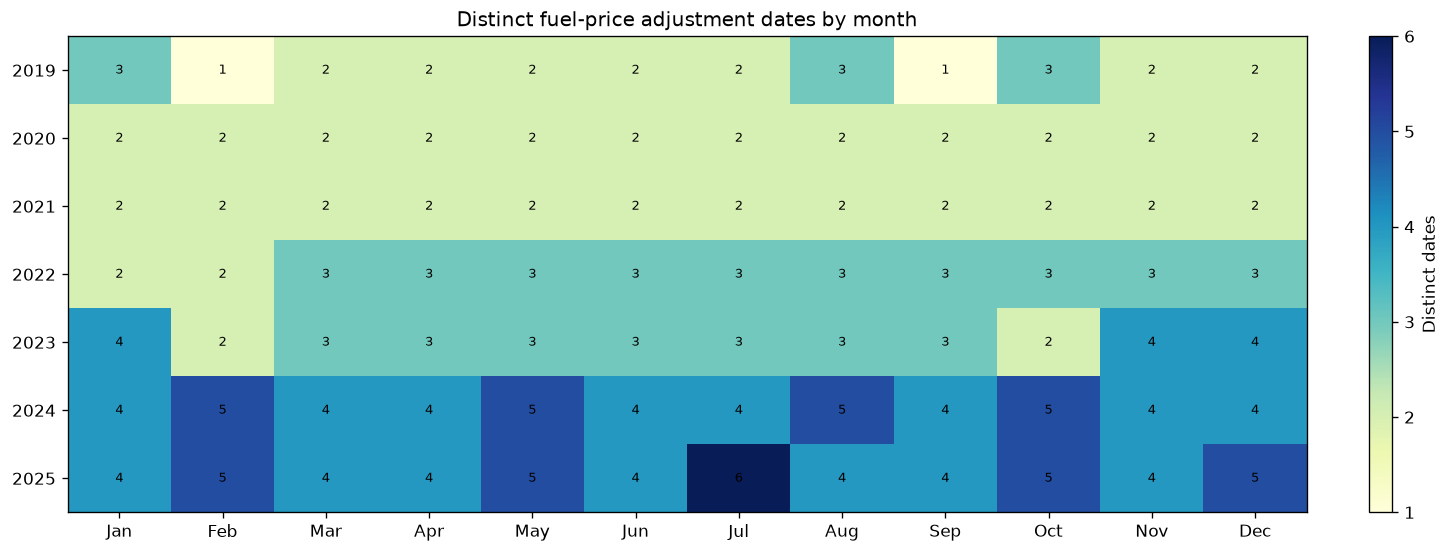

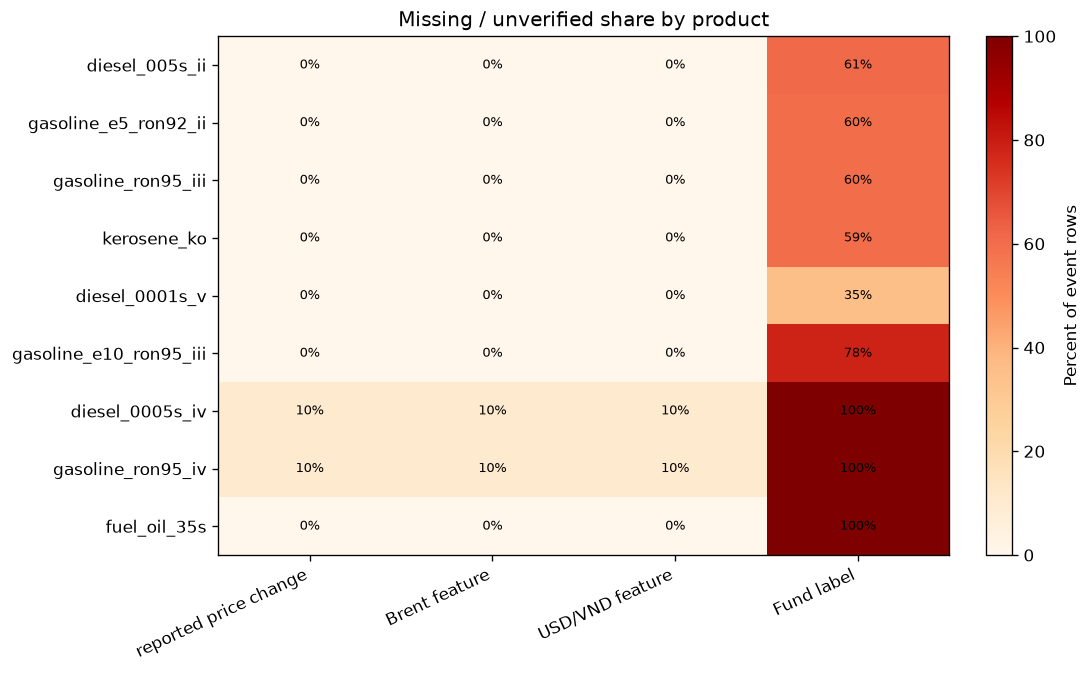

In [5]:
event_days = panel[["event_date"]].drop_duplicates().copy()
event_days["date"] = pd.to_datetime(event_days["event_date"])
complete = event_days.loc[event_days.date.dt.year.between(2019, 2025)].copy()
complete["year"] = complete.date.dt.year
complete["month"] = complete.date.dt.month
calendar = complete.groupby(["year", "month"]).size().unstack("month").reindex(
    index=range(2019, 2026), columns=range(1, 13), fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
im = ax.imshow(calendar.to_numpy(), aspect="auto", cmap="YlGnBu")
ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"] )
ax.set_yticks(range(len(calendar.index)), calendar.index)
for yi in range(calendar.shape[0]):
    for xi in range(calendar.shape[1]): ax.text(xi, yi, int(calendar.iat[yi,xi]), ha="center", va="center", fontsize=8)
ax.set_title("Distinct fuel-price adjustment dates by month")
fig.colorbar(im, ax=ax, label="Distinct dates")
fig.savefig(fig_dir / "04_adjustment_calendar.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

missing_columns = {"reported price change":"price_change_value", "Brent feature":"brent_usd_per_barrel",
                   "USD/VND feature":"usd_vnd_rate", "Fund label":"stabilization_fund_subsidy"}
missing = panel.groupby("product_id").agg({col:(lambda s: 100*s.isna().mean()) for col in missing_columns.values()})
missing = missing.rename(columns={v:k for k,v in missing_columns.items()}).reindex(product_summary.product_id)
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
im = ax.imshow(missing.to_numpy(), aspect="auto", cmap="OrRd", vmin=0, vmax=100)
ax.set_xticks(range(len(missing.columns)), missing.columns, rotation=25, ha="right")
ax.set_yticks(range(len(missing.index)), missing.index)
for yi in range(missing.shape[0]):
    for xi in range(missing.shape[1]): ax.text(xi, yi, f"{missing.iat[yi,xi]:.0f}%", ha="center", va="center", fontsize=8)
ax.set_title("Missing / unverified share by product")
fig.colorbar(im, ax=ax, label="Percent of event rows")
fig.savefig(fig_dir / "05_missingness_by_product.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)


## 5. Market context and exploratory association

Brent and USD/VND are shown on separate axes because units and scales differ. Association uses within-product Spearman correlation between reported fuel-price changes and changes in the strictly prior market value attached to successive fuel events. It is a screening diagnostic only.


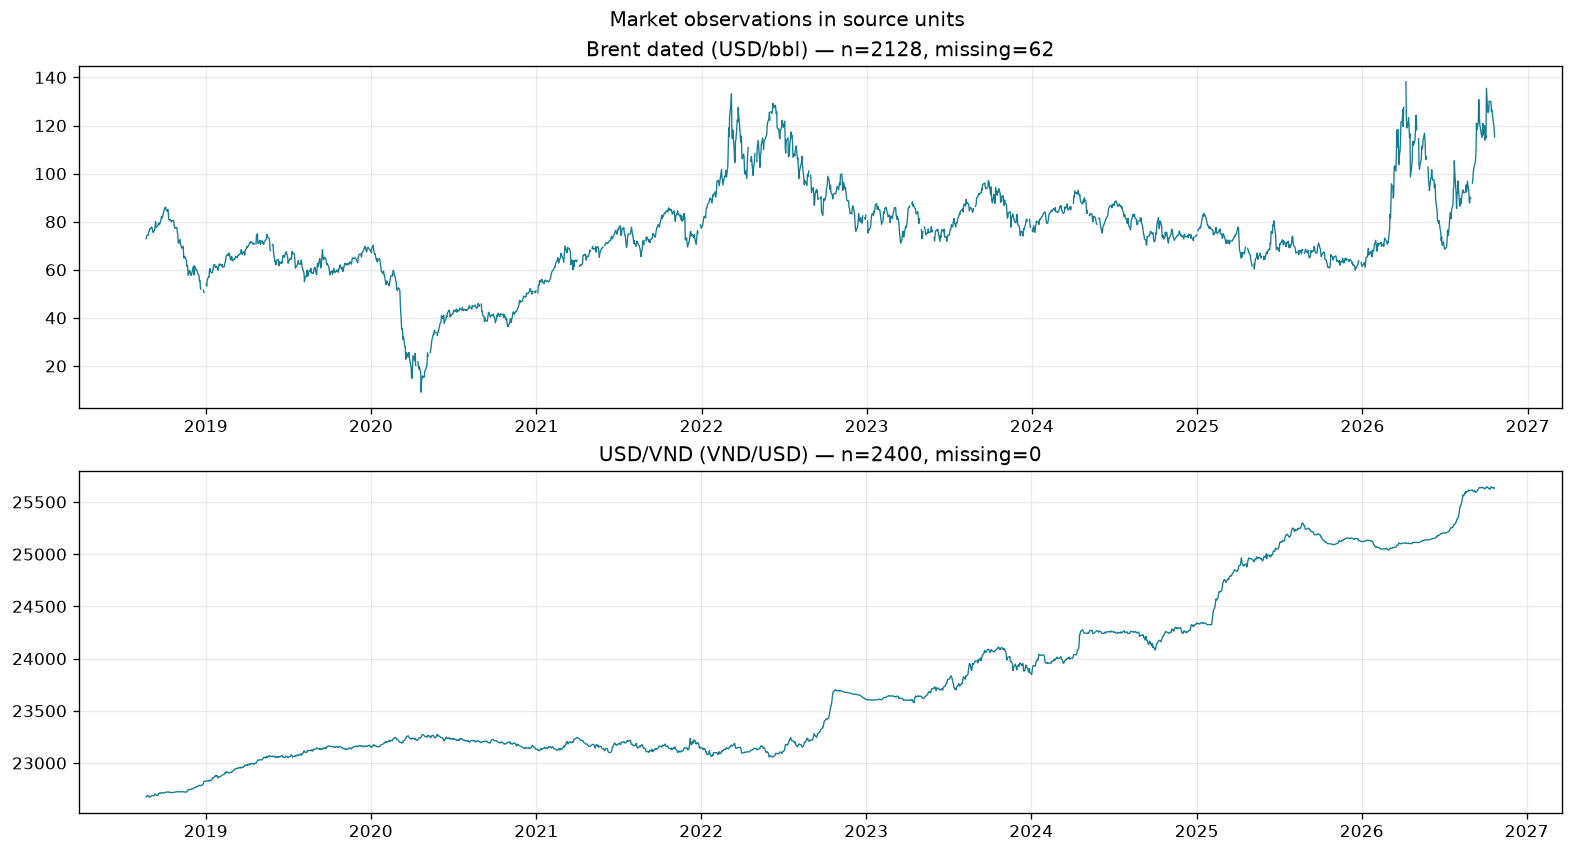

feature,brent_change,fx_change
product_id,,
diesel_005s_ii,308,308
gasoline_e5_ron92_ii,308,308
gasoline_ron95_iii,285,285
kerosene_ko,267,267
diesel_0001s_v,118,118
gasoline_e10_ron95_iii,73,73


feature,brent_change,fx_change
product_id,,
diesel_005s_ii,0.486,0.062
gasoline_e5_ron92_ii,0.494,0.069
gasoline_ron95_iii,0.507,0.054
kerosene_ko,0.537,0.040
diesel_0001s_v,0.346,0.108
gasoline_e10_ron95_iii,0.296,0.158


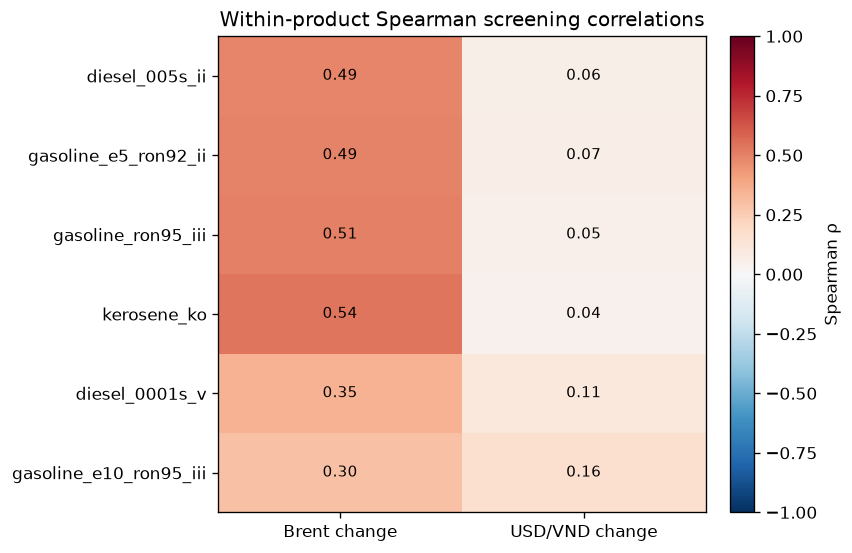

In [6]:
series_labels = {"brent_dated_usd_bbl":"Brent dated (USD/bbl)", "usd_vnd_sbv_reference":"USD/VND (VND/USD)"}
fig, axes = plt.subplots(2, 1, figsize=(13, 7), constrained_layout=True)
for ax, series_id in zip(axes, series_labels):
    group = market.loc[market.series_id.eq(series_id)].sort_values("observation_date")
    ax.plot(group.observation_date, group.value, linewidth=.8, color="#147d92")
    ax.set_title(f"{series_labels[series_id]} — n={len(group)}, missing={group.value.isna().sum()}")
    ax.grid(alpha=.25)
fig.suptitle("Market observations in source units")
fig.savefig(fig_dir / "06_market_series_history.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

association_rows = []
for product_id, group in panel.loc[panel.product_id.isin(eligible)].sort_values("effective_at_local").groupby("product_id"):
    delta = pd.DataFrame({"fuel_change":group.price_change_value.to_numpy(),
                          "brent_change":group.brent_usd_per_barrel.diff().to_numpy(),
                          "fx_change":group.usd_vnd_rate.diff().to_numpy()})
    for feature in ["brent_change", "fx_change"]:
        pair = delta[["fuel_change", feature]].dropna()
        association_rows.append({"product_id":product_id, "feature":feature, "paired_events":len(pair),
                                 "spearman_rho":pair.fuel_change.corr(pair[feature], method="spearman") if len(pair)>=3 else np.nan})
associations = pd.DataFrame(association_rows)
association_matrix = associations.pivot(index="product_id", columns="feature", values="spearman_rho").reindex(eligible)
display(associations.pivot(index="product_id", columns="feature", values="paired_events").reindex(eligible))
display(association_matrix.round(3))
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
im = ax.imshow(association_matrix.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(association_matrix.columns)), ["Brent change", "USD/VND change"] )
ax.set_yticks(range(len(association_matrix.index)), association_matrix.index)
for yi in range(association_matrix.shape[0]):
    for xi in range(association_matrix.shape[1]): ax.text(xi, yi, f"{association_matrix.iat[yi,xi]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Within-product Spearman screening correlations")
fig.colorbar(im, ax=ax, label="Spearman ρ")
fig.savefig(fig_dir / "07_exploratory_associations.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)


## Findings and limits

- Preserve the event grain: there are no daily target rows between adjustments.
- Coverage is uneven across products; sparse/discontinued grades should not support strong conclusions.
- Treat missing Brent/FX and unverified fund labels as NULL. Quarantine remains outside model data.
- The heatmap associations are neither causal estimates nor model validation. Confirm target, forecast horizon, and as-of cutoff with M3 before feature engineering.
- The exact run ID, full metrics, charts, and acceptance caveats are summarized in [`reports/eda-summary.md`](../../reports/eda-summary.md).
